<a href="https://colab.research.google.com/github/ivaniselima-dev/pibic-sage-processm/blob/main/01_execucao_sage.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
# ETAPA 1 - Baixar o código do SAGE do GitHub
!git clone https://github.com/tudelft-cda-lab/SAGE
# Entrar na pasta do SAGE: todos os comandos seguintes rodam dentro dela
%cd SAGE

Cloning into 'SAGE'...
remote: Enumerating objects: 820, done.
remote: Counting objects: 100% (238/238), done.
remote: Compressing objects: 100% (72/72), done.
remote: Total 820 (delta 184), reused 195 (delta 160), pack-reused 582 (from 1)
Receiving objects: 100% (820/820), 93.69 MiB | 25.35 MiB/s, done.
Resolving deltas: 100% (464/464), done.
/content/SAGE/SAGE


In [10]:
# ETAPA 2 - Baixar e compilar o FlexFringe
# O FlexFringe é a ferramenta externa que aprende o modelo (S-PDFA) a partir das sequências de ataque
!git clone https://github.com/tudelft-cda-lab/FlexFringe
# Usar a versão de 2022 (1a87e3b): a versão mais nova é incompatível com o formato que o SAGE gera
!cd FlexFringe && git checkout 1a87e3b && make clean all
# Copiar o arquivo de configuração do SAGE para dentro do FlexFringe
!cp spdfa-config.ini FlexFringe/ini/

Cloning into 'FlexFringe'...
remote: Enumerating objects: 11198, done.
remote: Counting objects: 100% (868/868), done.
remote: Compressing objects: 100% (206/206), done.
remote: Total 11198 (delta 725), reused 720 (delta 660), pack-reused 10330 (from 2)
Receiving objects: 100% (11198/11198), 43.70 MiB | 16.34 MiB/s, done.
Resolving deltas: 100% (7653/7653), done.
Updating files: 100% (2236/2236), done.
Note: switching to '1a87e3b'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at 1a87e3b =fixed sink printing
rm 

In [11]:
# ETAPA 3 - Preparar os dados
# Descompactar os alertas de intrusão (datasets de competições de ataque CPTC e CCDC)
!find alerts/ -name '*.gz' | xargs gunzip
# Instalar o Graphviz, que desenha os grafos de ataque
!apt-get install -y graphviz

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-9ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.


In [12]:
# ETAPA 4 - Executar o SAGE
# Entrada: alertas do CPTC-2018 (6 equipes atacantes)
# Saída: grafos de ataque na pasta exp-2018AGs
!MPLBACKEND=Agg python sage.py alerts/cptc-2018/ exp-2018 --dataset cptc --keep-files

------ Downloading the IANA port-service mapping ------
------ Reading alerts ------
About to read json files...
suricata_alert_t7
Reading # alerts:  10001
Filtered # alerts (remaining): 8517
suricata_alert_t5
Reading # alerts:  18447
Filtered # alerts (remaining): 11918
suricata_alert_t1
Reading # alerts:  39710
Filtered # alerts (remaining): 26651
suricata_alert_t9
Reading # alerts:  12841
Filtered # alerts (remaining): 10081
suricata_alert_t8
Reading # alerts:  15560
Filtered # alerts (remaining): 9037
suricata_alert_t2
Reading # alerts:  5012
Filtered # alerts (remaining): 4922
------ Converting to episodes ------
---------------- TEAMS -------------------------
0 1 2 3 4 5 
------ Converting to episode sequences ------
# teams: 6
----- TEAMS -----
0 1 2 3 4 5 
# episode sequences: 42
------ Breaking into sub-sequences and generating traces ------
----- Sub-sequences -----
1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40

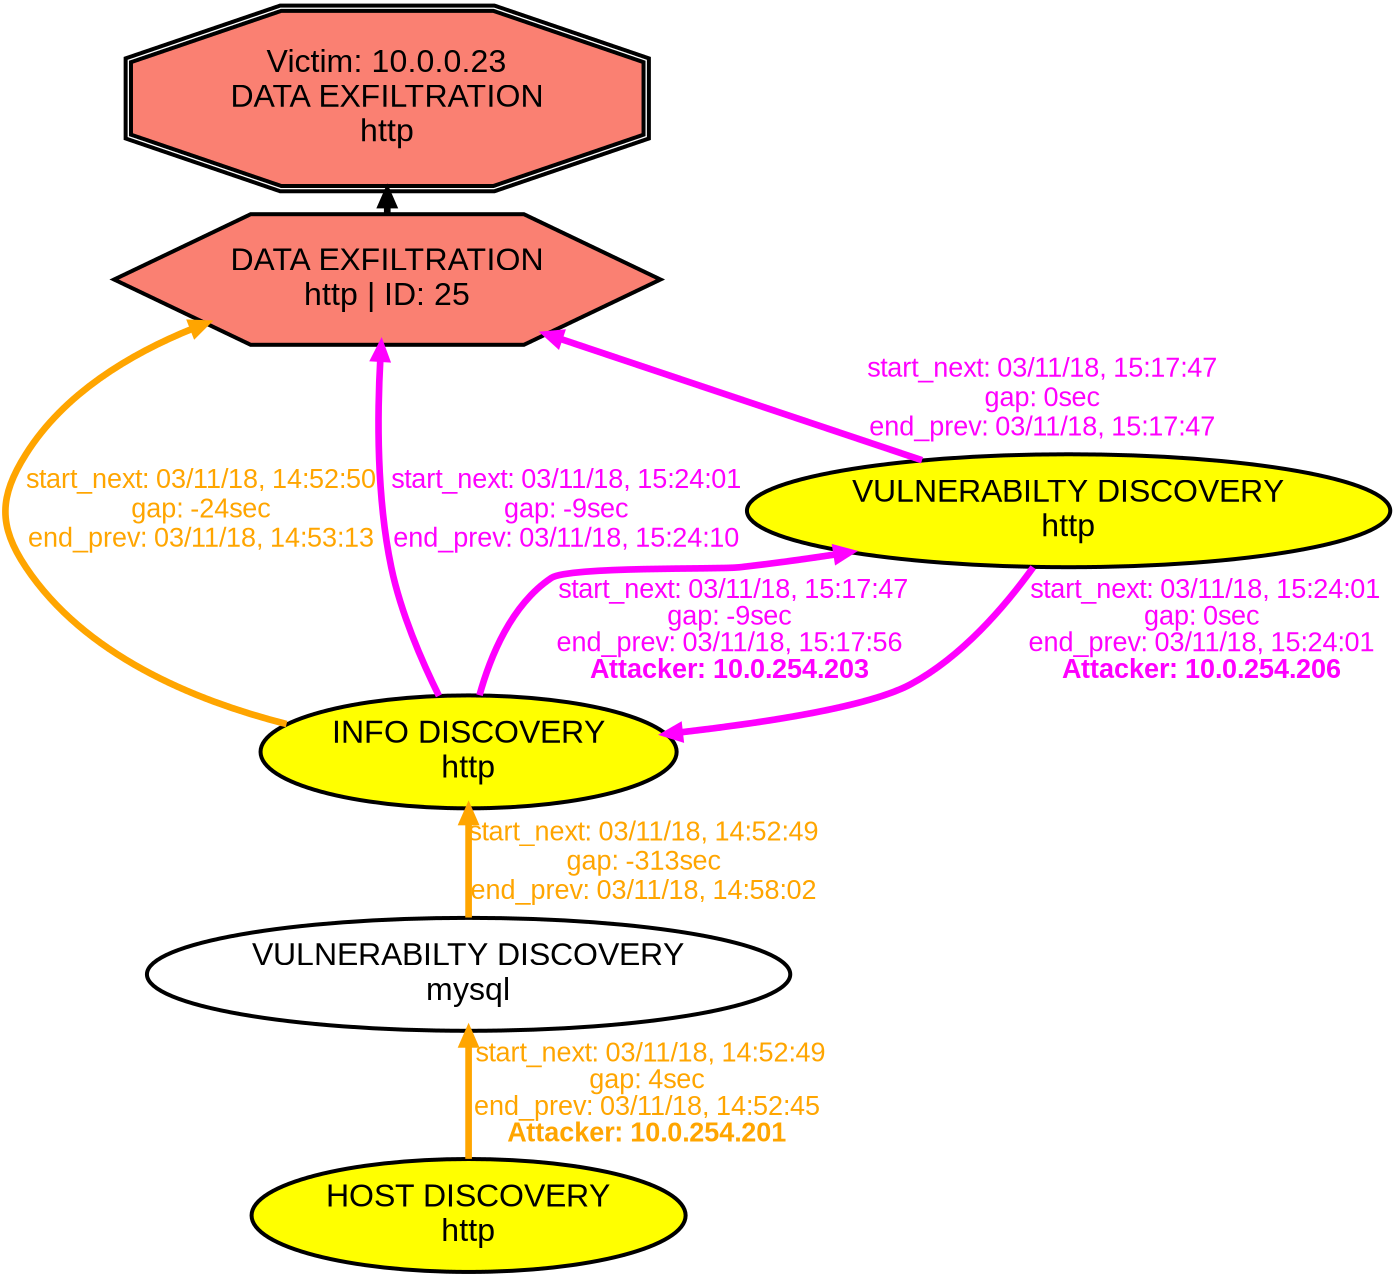

In [13]:
# ETAPA 5 - Mostrar um grafo de ataque gerado
# Vítima 10.0.0.23, objetivo atingido: roubo de dados (data exfiltration) via http
from IPython.display import Image
Image('exp-2018AGs/exp-2018.txt-attack-graph-for-victim-10.0.0.23-DATAEXFILTRATIONhttp.png')